# Feature Engineering
## Decision Tree Pruning and Hyperparameter Tuning with GridSearch

In machine learning, feature engineering is the process of transforming raw data into meaningful features that improve model performance. This provides the algorithm with important information, helping it to detect patterns and make more accurate predictions. Techniques include scaling, encoding and creating new features from existing data.

Decision tree pruning is the process of trimming down a decision tree to reduce its complexity and prevent overfitting. Pruning is applied to prevent overfitting by removing unnecessary branches to make the model simpler and better at generalizing to new data. This improves accuracy, efficiency, and interpretability. It can be achieved by setting a maximum depth or a minimum sample per leaf, or by using cost-complexity pruning.

Hyperparameter tuning with GridSearch is a method of optimizing a model's hyperparameters by systematically testing different combinations within a specified range. This ensures that the model neither underfits nor overfits, maximizing its performance and generalization to new data. Cross-validation is typically used in this process to find the best set of hyperparameters for improved accuracy.

The Titanic dataset is intended for use in:

In [18]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, accuracy_score

## T1
Load the dataset using the pandas.read_csv(…) function.

In [2]:
ds_initial = pd.read_csv('titanic_dataset.csv')

In [4]:
ds_initial.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## T2
Apply feature engineering and exploratory data analysis procedures.

### 2.1 Visão geral e valores em falta

In [6]:
ds_initial.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [7]:
ds_initial.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
PassengerId,891.0,NaN,NaN,NaN,446.0,257.353842,1.0,223.5,446.0,668.5,891.0
Survived,891.0,NaN,NaN,NaN,0.383838,0.486592,0.0,0.0,0.0,1.0,1.0
Pclass,891.0,NaN,NaN,NaN,2.308642,0.836071,1.0,2.0,3.0,3.0,3.0
Name,891,891,"Braund, Mr. Owen Harris",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sex,891,2,male,577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,714.0,NaN,NaN,NaN,29.699118,14.526497,0.42,20.125,28.0,38.0,80.0
SibSp,891.0,NaN,NaN,NaN,0.523008,1.102743,0.0,0.0,0.0,1.0,8.0
Parch,891.0,NaN,NaN,NaN,0.381594,0.806057,0.0,0.0,0.0,0.0,6.0
Ticket,891,681,347082,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fare,891.0,NaN,NaN,NaN,32.204208,49.693429,0.0,7.9104,14.4542,31.0,512.3292


          n_null     %
Age          177  19.9
Cabin        687  77.1
Embarked       2   0.2


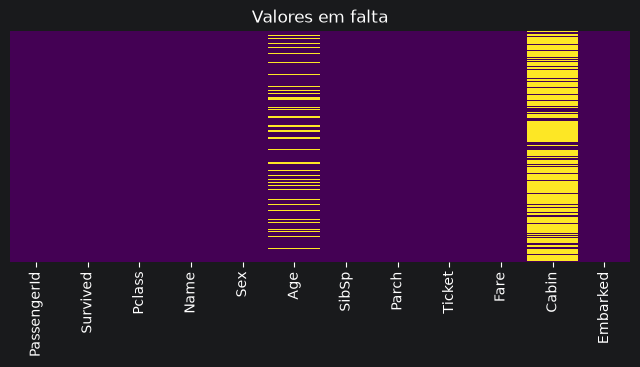

In [8]:
# valores em falta (nº e %)
missing = ds_initial.isnull().sum()
print(pd.DataFrame({"n_null": missing, "%": (missing/len(ds_initial)*100).round(1)}).query("n_null > 0"))

plt.figure(figsize=(8,3))
sns.heatmap(ds_initial.isnull(), yticklabels=False, cbar=False, cmap="viridis")
plt.title("Valores em falta"); plt.show()

In [10]:
# valores únicos por coluna (colunas com 1 só valor ou 1 valor por linha não ajudam)
ds_initial.nunique()

PassengerId    891
Survived         2
Pclass           3
Name           891
Sex              2
Age             88
SibSp            7
Parch            7
Ticket         681
Fare           248
Cabin          147
Embarked         3
dtype: int64

**Decisões de limpeza**
- `PassengerId`, `Ticket`: identificadores, sem valor preditivo → remover.
- `Cabin`: ~77 % em falta → remover (ou criar `HasCabin`, ver abaixo).
- `Name`: não serve como está, mas contém o **título** (Mr, Mrs, Miss, Master…) → feature nova.
- `Age` (~20 % em falta) → imputar; `Embarked` (2 em falta) → moda.

### 2.2 Criação de novas features

In [11]:
df = ds_initial.copy()

# Título extraído do nome e agrupado
df["Title"] = df["Name"].str.extract(r",\s*([^\.]+)\.", expand=False).str.strip()
rare = ["Dr","Rev","Col","Major","Capt","Don","Dona","Jonkheer","Sir","Lady","the Countess"]
df["Title"] = (df["Title"].replace(rare, "Rare")
                          .replace({"Mlle":"Miss","Ms":"Miss","Mme":"Mrs"}))
print(df["Title"].value_counts())

# Tamanho da família e viajar sozinho
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1
df["IsAlone"]    = (df["FamilySize"] == 1).astype(int)

# Tinha cabine registada?
df["HasCabin"] = df["Cabin"].notnull().astype(int)

Title
Mr        517
Miss      185
Mrs       126
Master     40
Rare       23
Name: count, dtype: int64


### 2.3 Tratamento de valores em falta

In [12]:
# Age: mediana por título (mais informativo do que a mediana global)
df["Age"] = df["Age"].fillna(df.groupby("Title")["Age"].transform("median"))
df["Age"] = df["Age"].fillna(df["Age"].median())

df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])
df["Fare"]     = df["Fare"].fillna(df["Fare"].median())

# remover colunas inúteis
df = df.drop(columns=["PassengerId","Name","Ticket","Cabin"], errors="ignore")
print(df.isnull().sum().sum(), "valores em falta restantes")

0 valores em falta restantes


### 2.4 EDA

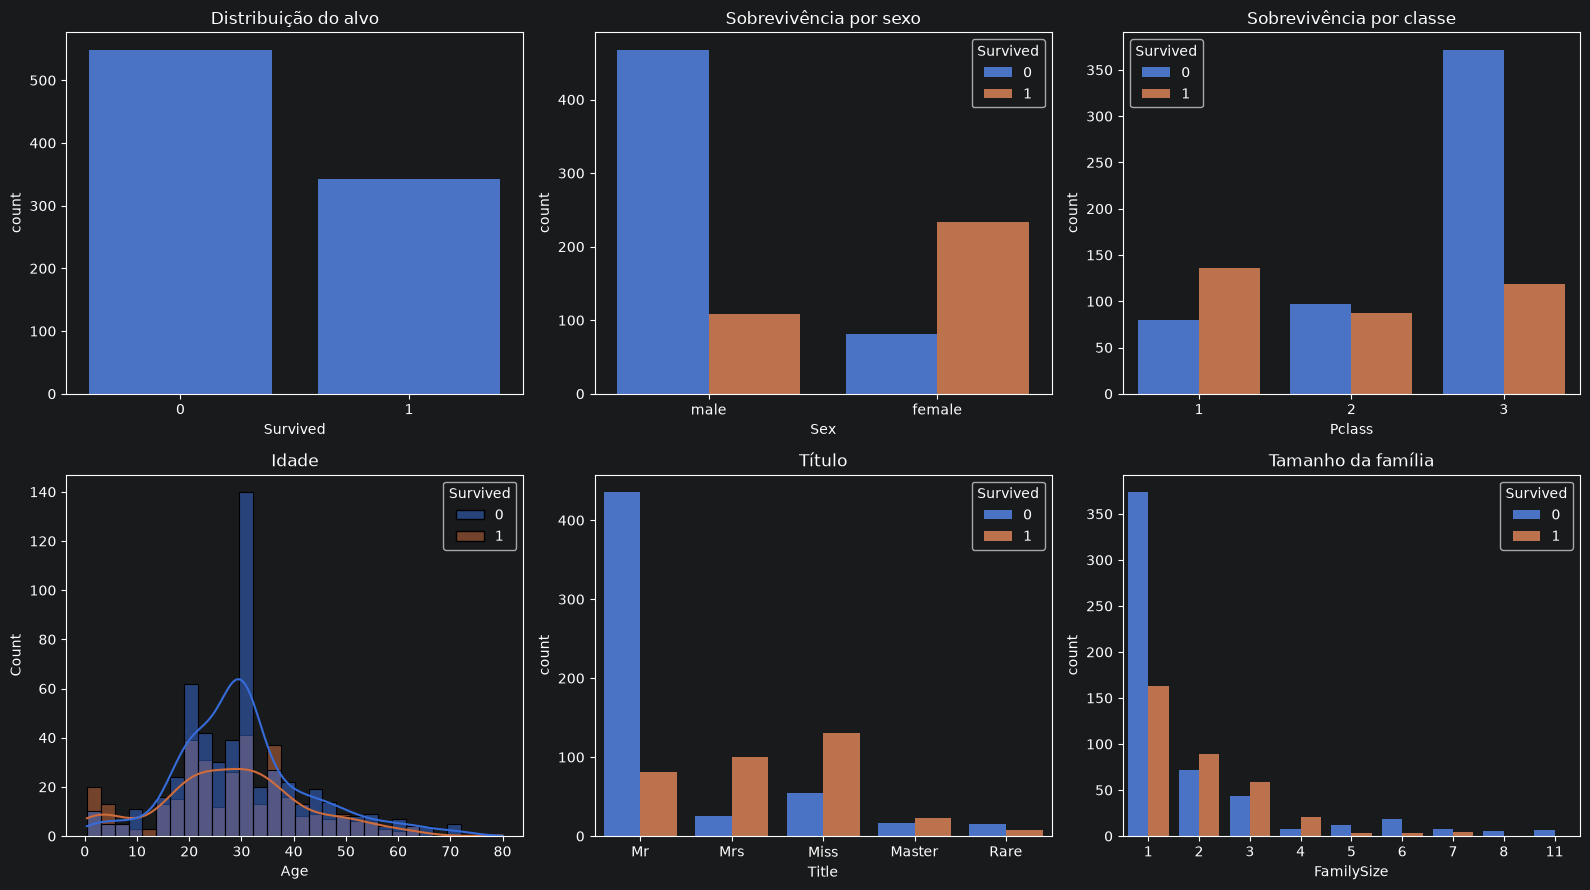

Survived
0    0.616
1    0.384
Name: proportion, dtype: float64


In [13]:
fig, ax = plt.subplots(2, 3, figsize=(16,9))
sns.countplot(x="Survived", data=df, ax=ax[0,0]);                 ax[0,0].set_title("Distribuição do alvo")
sns.countplot(x="Sex", hue="Survived", data=df, ax=ax[0,1]);      ax[0,1].set_title("Sobrevivência por sexo")
sns.countplot(x="Pclass", hue="Survived", data=df, ax=ax[0,2]);   ax[0,2].set_title("Sobrevivência por classe")
sns.histplot(data=df, x="Age", hue="Survived", bins=30, kde=True, ax=ax[1,0]); ax[1,0].set_title("Idade")
sns.countplot(x="Title", hue="Survived", data=df, ax=ax[1,1]);    ax[1,1].set_title("Título")
sns.countplot(x="FamilySize", hue="Survived", data=df, ax=ax[1,2]); ax[1,2].set_title("Tamanho da família")
plt.tight_layout(); plt.show()

print(df["Survived"].value_counts(normalize=True).round(3))   # balanceamento

### 2.5 Encoding de variáveis categóricas

In [14]:
# Sex -> binária; Embarked e Title -> one-hot (não têm ordem natural)
df["Sex"] = df["Sex"].map({"male": 0, "female": 1})
df = pd.get_dummies(df, columns=["Embarked", "Title"], drop_first=True, dtype=int)
df.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,FamilySize,IsAlone,HasCabin,Embarked_Q,Embarked_S,Title_Miss,Title_Mr,Title_Mrs,Title_Rare
0,0,3,0,22.0,1,0,7.2500,2,0,0,0,1,0,1,0,0
1,1,1,1,38.0,1,0,71.2833,2,0,1,0,0,0,0,1,0
2,1,3,1,26.0,0,0,7.9250,1,1,0,0,1,1,0,0,0
3,1,1,1,35.0,1,0,53.1000,2,0,1,0,1,0,0,1,0
4,0,3,0,35.0,0,0,8.0500,1,1,0,0,1,0,1,0,0


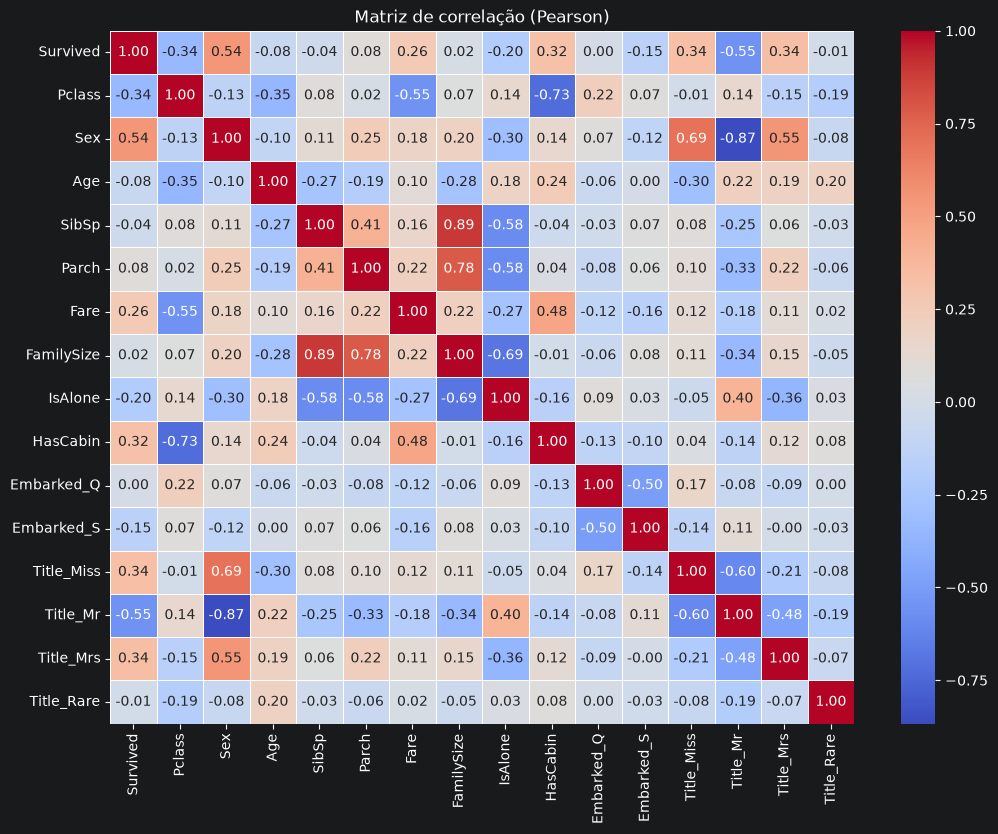

Survived      1.000000
Sex           0.543351
Title_Mrs     0.341994
Title_Miss    0.335636
HasCabin      0.316912
Fare          0.257307
Parch         0.081629
FamilySize    0.016639
Embarked_Q    0.003650
Title_Rare   -0.012054
SibSp        -0.035322
Age          -0.078931
Embarked_S   -0.149683
IsAlone      -0.203367
Pclass       -0.338481
Title_Mr     -0.549199
Name: Survived, dtype: float64


In [15]:
# Correlações
plt.figure(figsize=(12,9))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", linewidths=.5)
plt.title("Matriz de correlação (Pearson)"); plt.show()

print(df.corr()["Survived"].sort_values(ascending=False))

> Nota: árvores de decisão **não precisam de scaling/normalização** (ver slides da aula), por isso não escalamos.
> Redundâncias como `FamilySize` vs `SibSp`/`Parch` não prejudicam muito uma árvore, mas podem-se testar removidas.

## T3
Define the set of input and output variables for the model.

In [16]:
X = df.drop(columns=["Survived"])
y = df["Survived"]
print(X.shape, y.shape)
print(list(X.columns))

(891, 15) (891,)
['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'FamilySize', 'IsAlone', 'HasCabin', 'Embarked_Q', 'Embarked_S', 'Title_Miss', 'Title_Mr', 'Title_Mrs', 'Title_Rare']


## T4
Prepare and organize the set of case studies from the dataset into training and test data, using the sklearn.model_selection.train_test_split function.

In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=2021, stratify=y)   # stratify mantém a proporção das classes
print(X_train.shape, X_test.shape)

(623, 15) (268, 15)


## T5
Train the decision tree classifier model ( sklearn.tree_DecisionTreeClassifier) using the training data.

In [20]:
dt_model = DecisionTreeClassifier(random_state=2021)
dt_model.fit(X_train, y_train)
print("Profundidade:", dt_model.get_depth(), "| Nº de folhas:", dt_model.get_n_leaves())

Profundidade: 20 | Nº de folhas: 149


## T6
Plot the resulting tree and evaluate the model using the classification report and the confusion matrix.

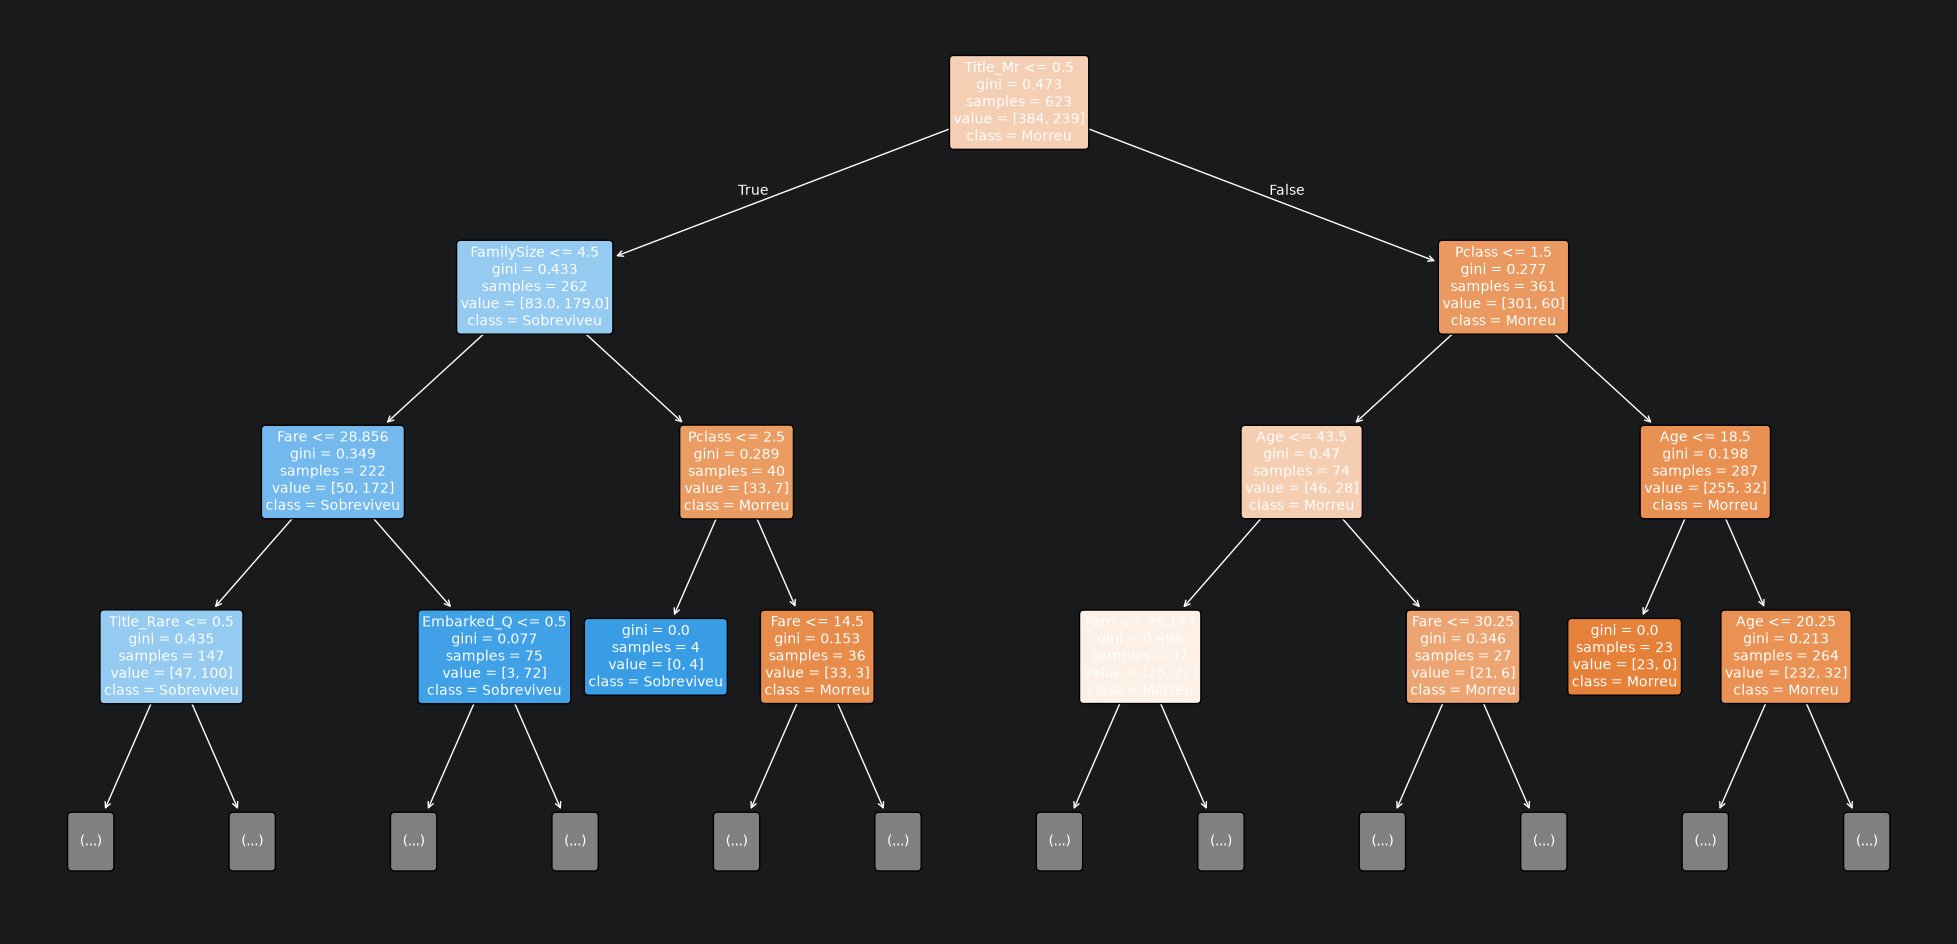

In [21]:
fig = plt.figure(figsize=(25,12))
plot_tree(dt_model, max_depth=3, feature_names=X.columns, class_names=["Morreu","Sobreviveu"],
          filled=True, rounded=True, fontsize=10)
plt.show()
fig.savefig("dt_plot.png", dpi=150)

===== T6 – Base (sem restrições) =====
Accuracy treino: 0.984 | teste: 0.765
              precision    recall  f1-score   support

      Morreu       0.81      0.81      0.81       165
  Sobreviveu       0.70      0.69      0.69       103

    accuracy                           0.76       268
   macro avg       0.75      0.75      0.75       268
weighted avg       0.76      0.76      0.76       268



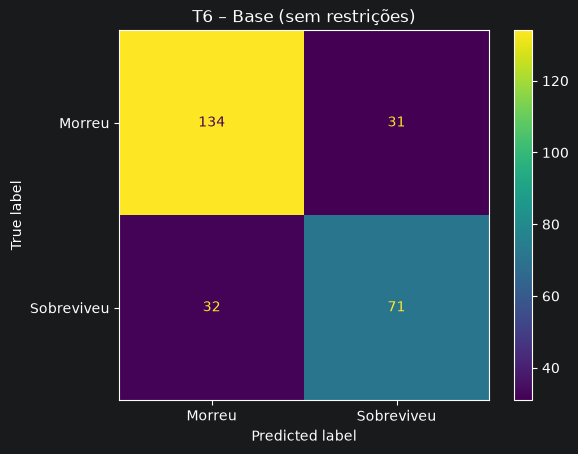

In [22]:
def avalia(modelo, nome):
    """Imprime report, matriz de confusão e devolve métricas para a tabela final."""
    pred = modelo.predict(X_test)
    print(f"===== {nome} =====")
    print(f"Accuracy treino: {modelo.score(X_train, y_train):.3f} | teste: {accuracy_score(y_test, pred):.3f}")
    print(classification_report(y_test, pred, target_names=["Morreu","Sobreviveu"]))
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["Morreu","Sobreviveu"])
    plt.title(nome); plt.show()
    rep = classification_report(y_test, pred, output_dict=True)
    return {"Modelo": nome,
            "Acc treino": modelo.score(X_train, y_train),
            "Acc teste": accuracy_score(y_test, pred),
            "F1 macro": rep["macro avg"]["f1-score"],
            "Recall (sobreviveu)": rep["1"]["recall"],
            "Profundidade": modelo.get_depth(),
            "Folhas": modelo.get_n_leaves()}

resultados = [avalia(dt_model, "T6 – Base (sem restrições)")]

**Esperado:** accuracy de treino ≈ 1.00 e de teste bem inferior → **overfitting** (a árvore cresceu até decorar o treino).

## T7
Tune the model using GridSearchCV (sklearn.model_selection.GridSearchCV). Test hyperparameters such as the criterion, max_depth and min_samples_leaf.

In [24]:
param_grid = {
    "criterion": ["gini", "entropy"],
    "max_depth": list(range(1, 13)),
    "min_samples_leaf": [1, 2, 5, 10, 15, 20, 30],
}
grid_dt = GridSearchCV(DecisionTreeClassifier(random_state=2021), param_grid,
                       cv=5, scoring="accuracy", refit=True, verbose=1, n_jobs=-1)
grid_dt.fit(X_train, y_train)

print("Melhores hiperparâmetros:", grid_dt.best_params_)
print(f"Melhor accuracy CV: {grid_dt.best_score_:.3f}")

Fitting 5 folds for each of 168 candidates, totalling 840 fits
Melhores hiperparâmetros: {'criterion': 'gini', 'max_depth': 7, 'min_samples_leaf': 1}
Melhor accuracy CV: 0.830


In [25]:
# Top 5 combinações
cv_res = pd.DataFrame(grid_dt.cv_results_)
cols = ["param_criterion","param_max_depth","param_min_samples_leaf","mean_test_score","std_test_score"]
cv_res.sort_values("mean_test_score", ascending=False)[cols].head(5)

,param_criterion,param_max_depth,param_min_samples_leaf,mean_test_score,std_test_score
42,gini,7,1,0.829819,0.024227
49,gini,8,1,0.823406,0.021737
154,entropy,11,1,0.813755,0.026002
56,gini,9,1,0.810594,0.016489
106,entropy,4,2,0.807381,0.010148


## T8
Evaluate the best-developed model and perform the corresponding critical analysis.

===== T8 – GridSearch =====
Accuracy treino: 0.891 | teste: 0.806
              precision    recall  f1-score   support

      Morreu       0.82      0.87      0.85       165
  Sobreviveu       0.77      0.70      0.73       103

    accuracy                           0.81       268
   macro avg       0.80      0.79      0.79       268
weighted avg       0.80      0.81      0.80       268



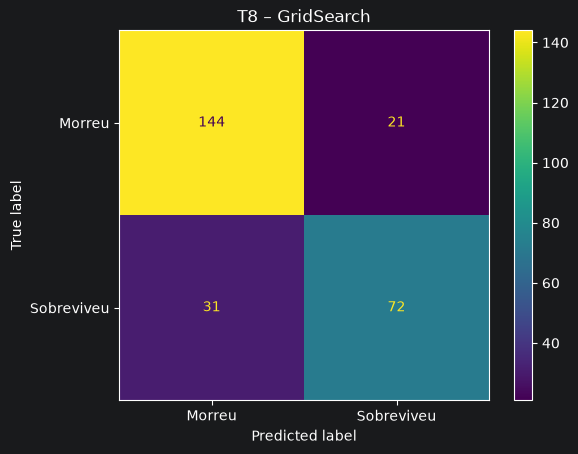

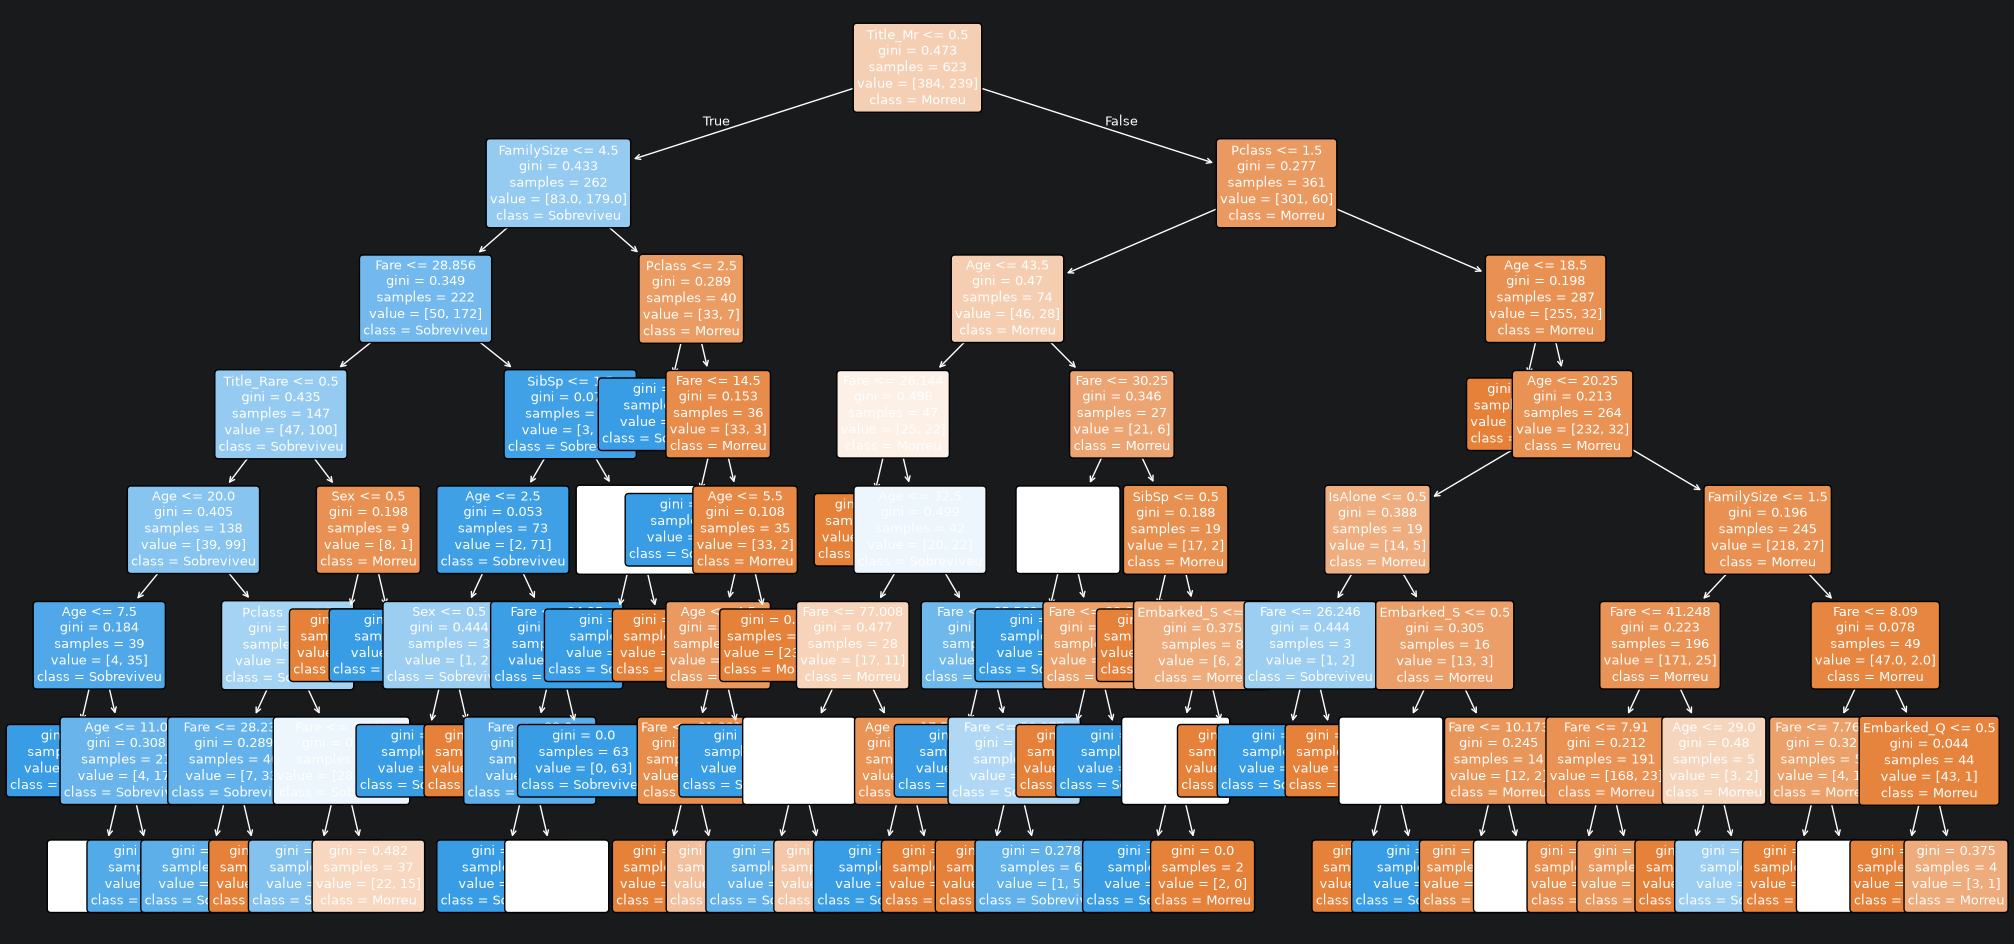

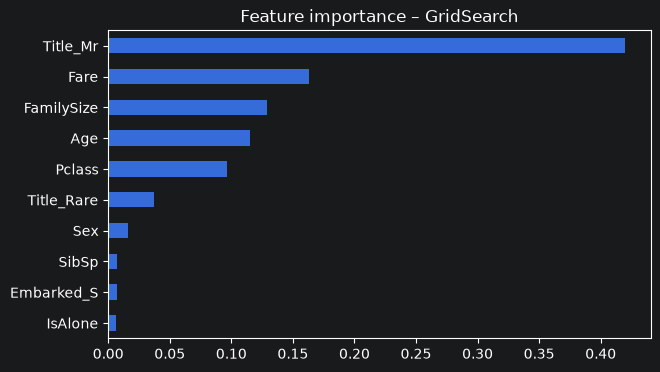

In [26]:
best_grid = grid_dt.best_estimator_
resultados.append(avalia(best_grid, "T8 – GridSearch"))

fig = plt.figure(figsize=(25,12))
plot_tree(best_grid, feature_names=X.columns, class_names=["Morreu","Sobreviveu"],
          filled=True, rounded=True, fontsize=9)
plt.show(); fig.savefig("dt_plot_grid.png", dpi=150)

# Importância das features
imp = pd.Series(best_grid.feature_importances_, index=X.columns).sort_values()
imp.tail(10).plot.barh(figsize=(7,4), title="Feature importance – GridSearch"); plt.show()

## T9
Apply the pruning technique to the first model. Try pre- and post-pruning using max_depth and ccp_alpha respectively

### 9.1 Pré-pruning: `max_depth`
Testam-se todas as profundidades de 1 até à profundidade da árvore completa (como nos slides).

Melhor max_depth: {'max_depth': 7} | acc CV = 0.830


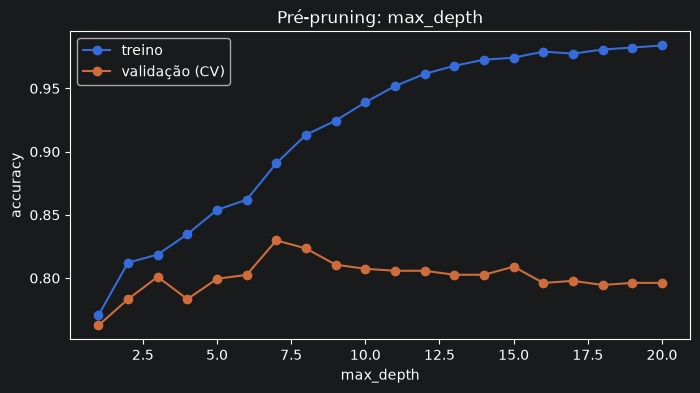

In [27]:
max_depth_full = dt_model.get_depth()
gs_depth = GridSearchCV(DecisionTreeClassifier(random_state=2021),
                        {"max_depth": list(range(1, max_depth_full + 1))},
                        cv=5, scoring="accuracy")
gs_depth.fit(X_train, y_train)
print("Melhor max_depth:", gs_depth.best_params_, f"| acc CV = {gs_depth.best_score_:.3f}")
pre_pruned = gs_depth.best_estimator_

# Curva accuracy vs max_depth
d = pd.DataFrame(gs_depth.cv_results_)
tr = [DecisionTreeClassifier(max_depth=k, random_state=2021).fit(X_train, y_train).score(X_train, y_train)
      for k in d["param_max_depth"]]
plt.figure(figsize=(8,4))
plt.plot(d["param_max_depth"], tr, "o-", label="treino")
plt.plot(d["param_max_depth"], d["mean_test_score"], "o-", label="validação (CV)")
plt.xlabel("max_depth"); plt.ylabel("accuracy"); plt.legend(); plt.title("Pré-pruning: max_depth"); plt.show()

### 9.2 Post-pruning: `ccp_alpha` (cost-complexity pruning)

In [28]:
path = dt_model.cost_complexity_pruning_path(X_train, y_train)
ccp_alphas = np.unique(path.ccp_alphas)[:-1]      # o último alpha dá uma árvore só com a raiz
print(len(ccp_alphas), "valores de alpha")

gs_ccp = GridSearchCV(DecisionTreeClassifier(random_state=2021),
                      {"ccp_alpha": ccp_alphas}, cv=5, scoring="accuracy", n_jobs=-1)
gs_ccp.fit(X_train, y_train)
print("Melhor ccp_alpha:", gs_ccp.best_params_, f"| acc CV = {gs_ccp.best_score_:.3f}")
post_pruned = gs_ccp.best_estimator_

58 valores de alpha
Melhor ccp_alpha: {'ccp_alpha': np.float64(0.002140181915462814)} | acc CV = 0.828


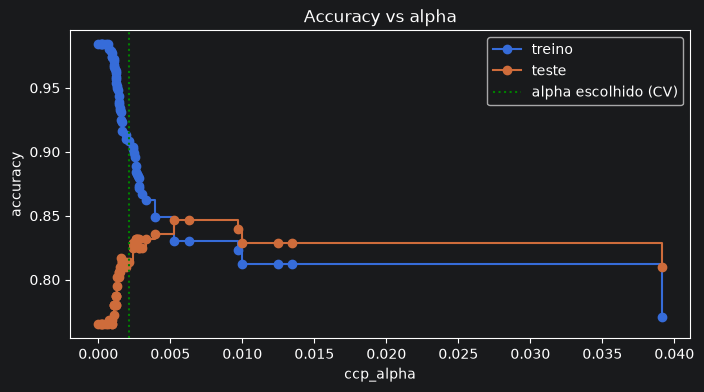

In [30]:
# Accuracy treino/teste vs alpha (como no slide 53)
trees = [DecisionTreeClassifier(random_state=2021, ccp_alpha=a).fit(X_train, y_train) for a in ccp_alphas]
plt.figure(figsize=(8,4))
plt.plot(ccp_alphas, [t.score(X_train, y_train) for t in trees], marker="o", ds="steps-post", label="treino")
plt.plot(ccp_alphas, [t.score(X_test,  y_test)  for t in trees], marker="o", ds="steps-post", label="teste")
plt.axvline(gs_ccp.best_params_["ccp_alpha"], color="g", ls=":", label="alpha escolhido (CV)")
plt.xlabel("ccp_alpha"); plt.ylabel("accuracy"); plt.legend(); plt.title("Accuracy vs alpha"); plt.show()

## T10
Repeat T8 to find the best models resulting from each pruning process.

===== T10 – Pré-pruning (max_depth=7) =====
Accuracy treino: 0.891 | teste: 0.806
              precision    recall  f1-score   support

      Morreu       0.82      0.87      0.85       165
  Sobreviveu       0.77      0.70      0.73       103

    accuracy                           0.81       268
   macro avg       0.80      0.79      0.79       268
weighted avg       0.80      0.81      0.80       268



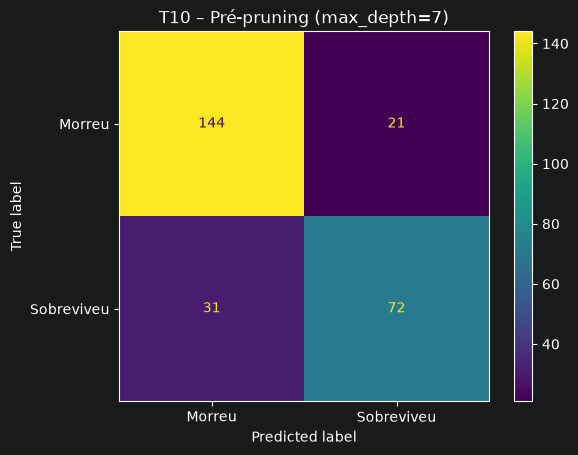

===== T10 – Post-pruning (ccp_alpha=0.00214) =====
Accuracy treino: 0.909 | teste: 0.813
              precision    recall  f1-score   support

      Morreu       0.84      0.87      0.85       165
  Sobreviveu       0.77      0.73      0.75       103

    accuracy                           0.81       268
   macro avg       0.80      0.80      0.80       268
weighted avg       0.81      0.81      0.81       268



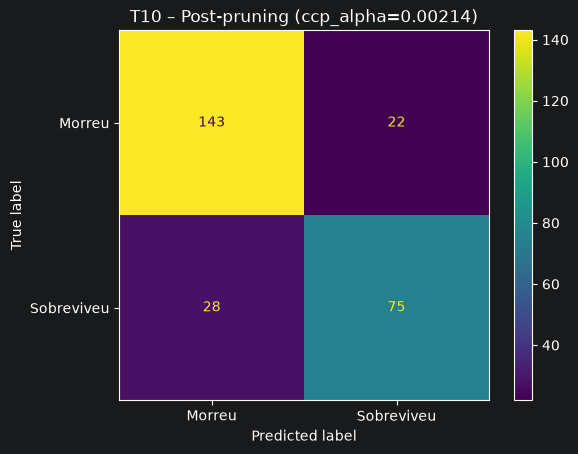

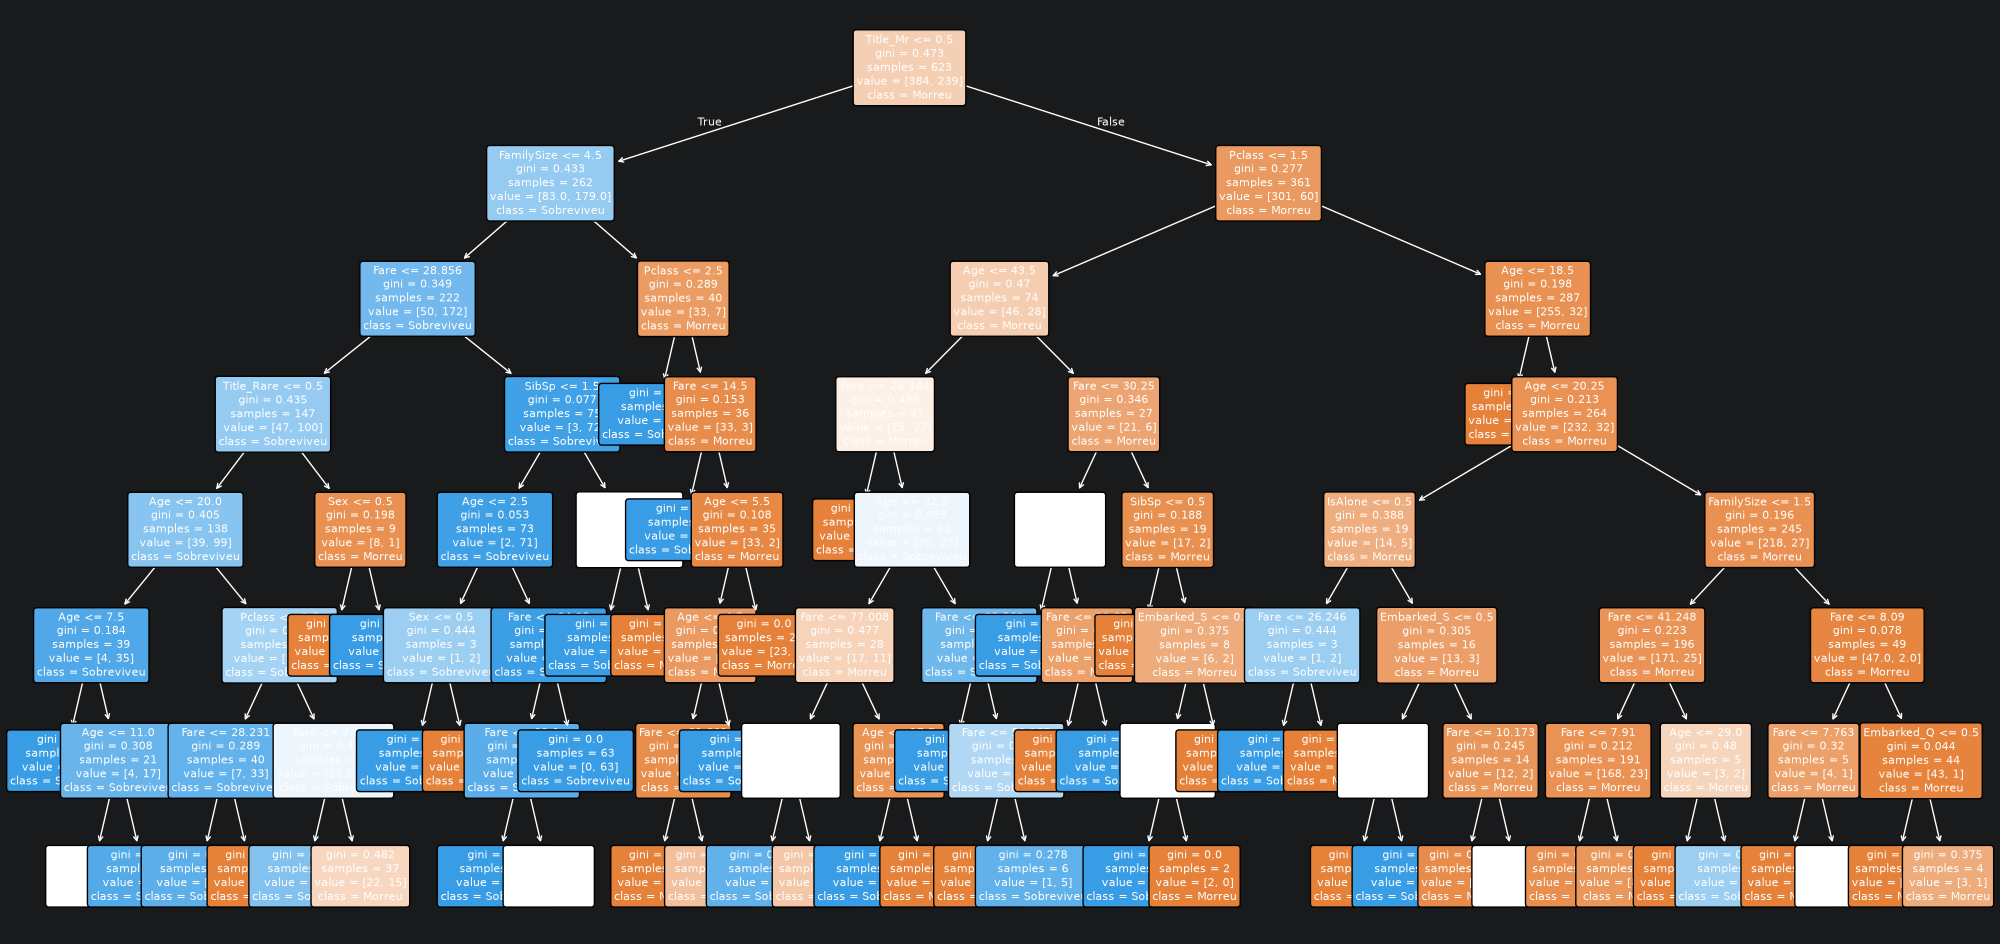

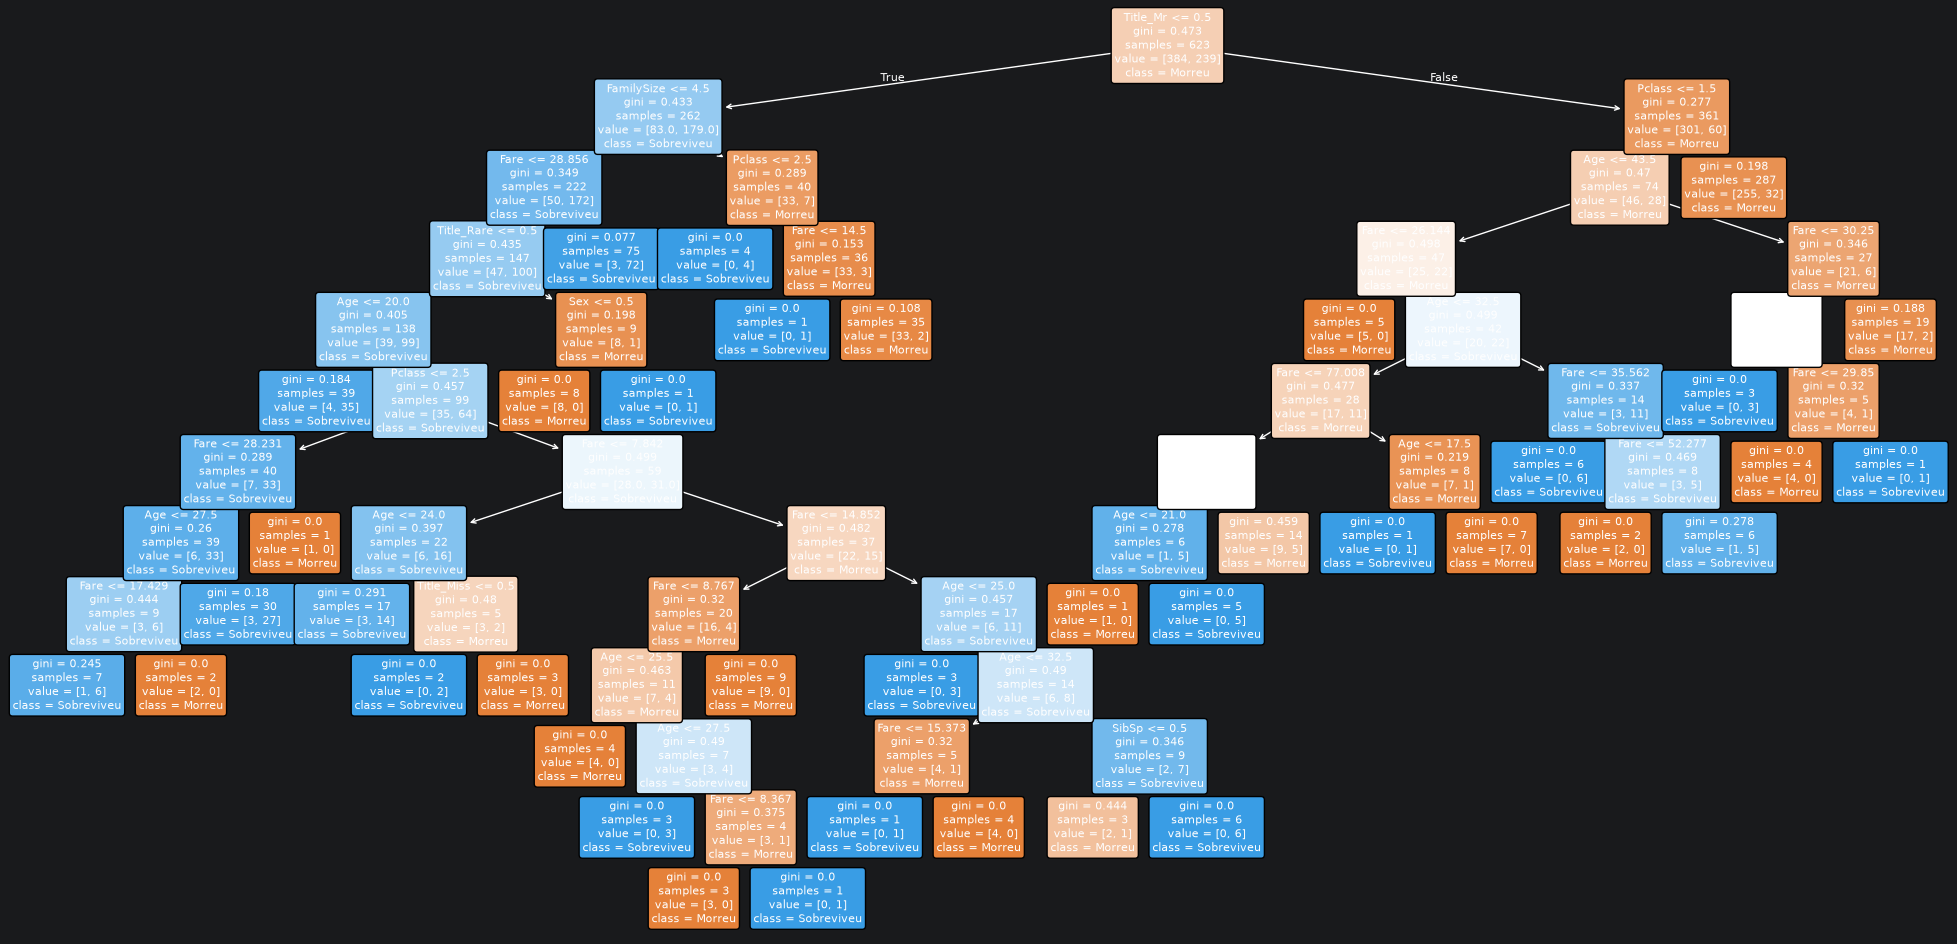

In [31]:
resultados.append(avalia(pre_pruned,  f"T10 – Pré-pruning (max_depth={pre_pruned.max_depth})"))
resultados.append(avalia(post_pruned, f"T10 – Post-pruning (ccp_alpha={post_pruned.ccp_alpha:.5f})"))

for m, nome in [(pre_pruned,"pre"),(post_pruned,"post")]:
    fig = plt.figure(figsize=(25,12))
    plot_tree(m, feature_names=X.columns, class_names=["Morreu","Sobreviveu"], filled=True, rounded=True, fontsize=8)
    plt.show(); fig.savefig(f"dt_plot_{nome}.png", dpi=150)

## T11
What conclusions did you draw from the results observed in T6, T8 and T10, what conclusions did you draw? In which situations do the model perform better? Which model is the best? Specify the set of parameters. Which model settings should be improved?

In [32]:
tabela = pd.DataFrame(resultados).set_index("Modelo").round(3)
tabela["Gap (treino-teste)"] = (tabela["Acc treino"] - tabela["Acc teste"]).round(3)
tabela

,Acc treino,Acc teste,F1 macro,Recall (sobreviveu),Profundidade,Folhas,Gap (treino-teste)
Modelo,,,,,,,
T6 – Base (sem restrições),0.984,0.765,0.751,0.689,20,149,0.219
T8 – GridSearch,0.891,0.806,0.791,0.699,7,52,0.085
T10 – Pré-pruning (max_depth=7),0.891,0.806,0.791,0.699,7,52,0.085
T10 – Post-pruning (ccp_alpha=0.00214),0.909,0.813,0.801,0.728,12,38,0.096


In [33]:
# Onde erra cada modelo? (por sexo e classe) – útil para responder a "em que situações performa melhor"
modelos = {"Base": dt_model, "GridSearch": best_grid, "Pré-pruning": pre_pruned, "Post-pruning": post_pruned}
Xt = X_test.copy(); Xt["correto"] = False
linhas = []
for nome, m in modelos.items():
    Xt["correto"] = (m.predict(X_test) == y_test)
    linhas.append(Xt.groupby("Sex")["correto"].mean().rename(lambda s: f"{nome} | {'Mulher' if s==1 else 'Homem'}"))
    linhas.append(Xt.groupby("Pclass")["correto"].mean().rename(lambda c: f"{nome} | Classe {c}"))
print(pd.concat(linhas).round(3).to_string())

Base | Homem               0.801
Base | Mulher              0.701
Base | Classe 1            0.781
Base | Classe 2            0.836
Base | Classe 3            0.727
GridSearch | Homem         0.865
GridSearch | Mulher        0.701
GridSearch | Classe 1      0.797
GridSearch | Classe 2      0.918
GridSearch | Classe 3      0.762
Pré-pruning | Homem        0.865
Pré-pruning | Mulher       0.701
Pré-pruning | Classe 1     0.797
Pré-pruning | Classe 2     0.918
Pré-pruning | Classe 3     0.762
Post-pruning | Homem       0.860
Post-pruning | Mulher      0.732
Post-pruning | Classe 1    0.797
Post-pruning | Classe 2    0.918
Post-pruning | Classe 3    0.776


T11 – Conclusões

T6 – Modelo base (sem restrições). A árvore cresceu até à profundidade 20, com 149 folhas. Tem accuracy de treino de 0.984 e de teste de 0.765, ou seja, um gap de 0.219. É um caso claro de overfitting: o modelo quase decorou o treino, mas não generaliza. Tem também o pior F1 macro (0.751) e o pior recall da classe “Sobreviveu” (0.689). Além disso, é uma árvore demasiado grande para ser interpretável.

T8 – Modelo com GridSearchCV. Os melhores hiperparâmetros foram criterion=____, max_depth=7 e min_samples_leaf=____. Em relação ao modelo base:

A profundidade desceu de 20 para 7 e as folhas de 149 para 52.
O gap baixou de 0.219 para 0.085.
A accuracy de teste subiu de 0.765 para 0.806 e o F1 macro de 0.751 para 0.791.

Limitar a complexidade da árvore regularizou o modelo: perdeu ajuste ao treino (0.984 → 0.891), mas ganhou capacidade de generalização, que é o que interessa.

T10 – Pruning.

Pré-pruning (max_depth=7) deu exatamente os mesmos resultados do GridSearch (mesma árvore, 52 folhas). Isto é coerente: o GridSearch também selecionou profundidade 7 e, com o mesmo random_state, a árvore resultante é a mesma.
Post-pruning (ccp_alpha≈____) obteve os melhores resultados de teste: accuracy 0.813, F1 macro 0.801 e recall de “Sobreviveu” 0.728. Tem apenas 38 folhas, a árvore mais pequena de todas, embora com profundidade 12. Ou seja, deixou a árvore crescer e cortou os ramos pouco úteis, em vez de impor um limite de profundidade igual em toda a árvore. O gap é de 0.096, ligeiramente superior ao do pré-pruning (0.085), mas com melhor desempenho em teste.

Em que situações o modelo se sai melhor?

Por sexo: os homens são os mais bem previstos (0.865 no GridSearch/pré-pruning, 0.860 no post-pruning). As mulheres são o ponto fraco (0.701 no base e no GridSearch). O post-pruning melhora este grupo para 0.732, e é a principal razão do seu melhor recall.
Por classe: a 2.ª classe é a mais fácil (0.918 nos modelos regularizados, contra 0.836 no base). A 3.ª classe é a mais difícil (0.727 no base; 0.762 e 0.776 nos restantes), e a 1.ª classe fica a meio (≈0.797).
Por classe do alvo: o recall de “Sobreviveu” (0.69–0.73) é inferior ao de quem não sobreviveu. O modelo falha cerca de 27–31 % dos sobreviventes, porque esta classe é minoritária e tem padrões mais heterogéneos.
Efeito da regularização: os modelos regularizados melhoram em todos os grupos face ao base, exceto nas mulheres com o GridSearch/pré-pruning, onde ficam iguais (0.701).

Qual é o melhor modelo? O post-pruning (ccp_alpha≈____). Tem a melhor accuracy de teste (0.813), o melhor F1 macro (0.801), o melhor recall de “Sobreviveu” (0.728), o melhor desempenho nas mulheres e na 3.ª classe, e é a árvore mais simples (38 folhas). Há uma ressalva: a vantagem sobre o GridSearch/pré-pruning é pequena (0.813 vs 0.806, cerca de 2 passageiros em 268 no teste), pelo que não deve ser lida como uma diferença estatisticamente significativa. O que é claro é que qualquer um dos três modelos regularizados é bastante melhor do que o base. Se se valorizar a simplicidade e a robustez, o pré-pruning (max_depth=7) é uma alternativa igualmente válida (gap mais baixo, 0.085).

O que melhorar?

Mais feature engineering: Fare por pessoa, deck da cabine, grupos de bilhete/família, e interações como sexo × classe.
Desbalanceamento: testar class_weight="balanced" para subir o recall de “Sobreviveu”.
Mais hiperparâmetros: min_samples_split, max_features e max_leaf_nodes, e uma grelha mais fina para ccp_alpha.
Avaliação mais robusta: usar validação cruzada repetida em vez de um único split treino/teste, para confirmar se as diferenças pequenas entre modelos são reais.
Outros modelos: as árvores são instáveis (uma pequena alteração nos dados pode mudar a estrutura), por isso vale a pena testar métodos ensemble como Random Forest ou Gradient Boosting.